# Goal:
compare training from scratch, feature extraction and partial fine-tuning, and study the effect of training-set size.

# Data:
CIFAR-10. 500 validation images per class (5,000 total), the official 10,000 test images, and stratified, nested training subsets of 500 / 2,000 / 10,000 / 45,000 images.





# Recommendations:
Feature extraction is the default when data is small. At 500 images it got 76% vs the CNN’s 41%, with only 12,810 trainable parameters.


Fine-tuning is only worth it with a lot of data when you need the highest accuracy. At 45k it added just +0.6 points for about 1.7 times the training time, and with small data it overfit immediately.


Custom CNN makes sense with a large dataset (45k), or when speed and model size matter. It’s about 3 times faster (1.6 vs ~5.2 ms) at the same accuracy, but a bad choice with little data



---



In [ ]:
# SETUP
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import time
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from tensorflow.keras import Sequential, layers, losses
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow import keras

from google.colab import drive
drive.mount("/content/drive")


BATCH_SIZE = 32
EPOCHS = 50
print("TensorFlow:", tf.__version__)

rng = np.random.default_rng(42)
tf.keras.utils.set_random_seed(42)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow: 2.21.0


In [ ]:
# Load & Normalize Data
import pickle
import tarfile

DATA_DIR = "/content/drive/MyDrive/archive/cifar-10-batches-py"

def read_batch(name):
    with open(f"{DATA_DIR}/{name}", "rb") as file:
        batch = pickle.load(file, encoding="bytes")
    images = batch[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
    labels = np.array(batch[b"labels"], dtype=np.uint8)
    return images, labels

batches = [read_batch(f"data_batch_{i}") for i in range(1, 6)]
X_data = np.concatenate([images for images, labels in batches])
y_data = np.concatenate([labels for images, labels in batches])
X_test_all, y_test_all = read_batch("test_batch")
del batches

class_names = np.array([
    "airplane", "car", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck",
])
print("Available images:", X_data.shape, X_test_all.shape)

Available images: (50000, 32, 32, 3) (10000, 32, 32, 3)


In [ ]:
#Data Split
val_indices = []
train_pools = []

for label in range(10):
    indices = np.flatnonzero(y_data == label)
    shuffled = rng.permutation(indices)
    val_indices.extend(shuffled[:500])
    train_pools.append(shuffled[500:])

X_val, y_val = X_data[val_indices], y_data[val_indices]
X_test, y_test = X_test_all, y_test_all


def get_train_subset(n_per_class):
    """Returns the first n images of each class"""
    idx = np.concatenate([pool[:n_per_class] for pool in train_pools])
    return X_data[idx], y_data[idx]

X_train, y_train = get_train_subset(50)

Training class counts: [50 50 50 50 50 50 50 50 50 50]
Validation class counts: [500 500 500 500 500 500 500 500 500 500]
Test class counts: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


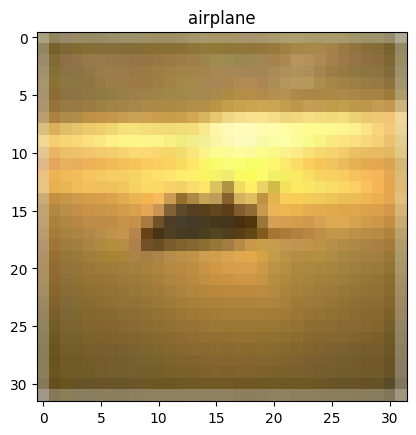

In [ ]:
# Check class counts, then display one image.
print("Training class counts:", np.bincount(y_train))
print("Validation class counts:", np.bincount(y_val))
print("Test class counts:", np.bincount(y_test))

plt.imshow(X_train[0])
plt.title(class_names[y_train[0]])
plt.show()

**A:** custom CNN, 3 conv blocks (32/64/128 filters), BatchNorm, global average pooling, 289,194 trainable parameters

In [ ]:
augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.1, 0.1),
], name="augmentation")


def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same")(x)
    x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(filters, 3, padding="same")(x)
    x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.25)(x)
    return x


def build_custom_cnn(augment=False):
    inputs = keras.Input(shape=(32, 32, 3))
    x = inputs
    if augment:
        x = augmentation(x)
    x = layers.Rescaling(1/255)(x)
    x = conv_block(x,32)
    x = conv_block(x,64)
    x = conv_block(x,128)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(10) (x)
    return keras.Model(inputs, outputs, name="custom_cnn")

In [ ]:
model = build_custom_cnn()
model.summary()

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_5 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_30          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_30 (ReLU)                 │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_31          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_31 (ReLU)                 │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_32          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_32 (ReLU)                 │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_33          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_33 (ReLU)                 │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_34          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_34 (ReLU)                 │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 290,090 (1.11 MB)

 Trainable params: 289,194 (1.10 MB)

 Non-trainable params: 896 (3.50 KB)

Test accuracy, macro-F1, trainable parameters, training time (C includes B’s stage), and single-image latency (median of 30 runs after warm-up, compiled with tf.function).

In [ ]:
def count_trainable(model):
  return int(sum(np.prod(w.shape) for w in model.trainable_weights))

def evaluate_model(model, X, y, n_timing=30):
  logits = model.predict(X, batch_size=256,verbose=0)
  y_pred = logits.argmax(axis=1)
  acc = accuracy_score(y, y_pred)
  f1 = f1_score(y,y_pred,average="macro")

  infer = tf.function(lambda x: model(x, training=False))
  one_image = tf.constant(X[:1])
  for _ in range(5):
    infer(one_image)

  times = []
  for _ in range(n_timing):
    start = time.perf_counter()
    infer(one_image).numpy()
    times.append(time.perf_counter() - start)
  latency = np.median(times)

  results = {
        "test_acc": acc,
        "macro_f1": f1,
        "latency_ms": latency * 1000,
        "fps": 1 / latency
  }

  return results,y_pred


AdamW, batch size 32, up to 50 epochs, early stopping (patience 10, best weights restored), ReduceLROnPlateau, seed 42 before each model.

In [ ]:
import time

def train_model(model, X_train, y_train, lr):
    model.compile(
        optimizer=AdamW(learning_rate=lr),
        loss=losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"],
    )
    callbacks = [
        EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3),
    ]
    start = time.perf_counter()
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=callbacks,
        verbose=2,
    )
    train_time = time.perf_counter() - start
    epochs_run = len(history.history["loss"])
    return history, train_time, epochs_run

Epoch 1/50
16/16 - 20s - 1s/step - accuracy: 0.1920 - loss: 2.9525 - val_accuracy: 0.1012 - val_loss: 2.7853 - learning_rate: 0.0010
Epoch 2/50
16/16 - 1s - 57ms/step - accuracy: 0.2180 - loss: 2.3464 - val_accuracy: 0.1460 - val_loss: 2.5230 - learning_rate: 0.0010
Epoch 3/50
16/16 - 1s - 57ms/step - accuracy: 0.2480 - loss: 2.1392 - val_accuracy: 0.2012 - val_loss: 2.1231 - learning_rate: 0.0010
Epoch 4/50
16/16 - 1s - 57ms/step - accuracy: 0.2980 - loss: 1.9096 - val_accuracy: 0.2390 - val_loss: 1.9503 - learning_rate: 0.0010
Epoch 5/50
16/16 - 1s - 66ms/step - accuracy: 0.2900 - loss: 1.9668 - val_accuracy: 0.3056 - val_loss: 1.8040 - learning_rate: 0.0010
Epoch 6/50
16/16 - 1s - 41ms/step - accuracy: 0.3220 - loss: 1.8857 - val_accuracy: 0.2594 - val_loss: 2.0299 - learning_rate: 0.0010
Epoch 7/50
16/16 - 1s - 43ms/step - accuracy: 0.3720 - loss: 1.7437 - val_accuracy: 0.3006 - val_loss: 1.8317 - learning_rate: 0.0010
Epoch 8/50
16/16 - 1s - 43ms/step - accuracy: 0.3880 - loss: 1.

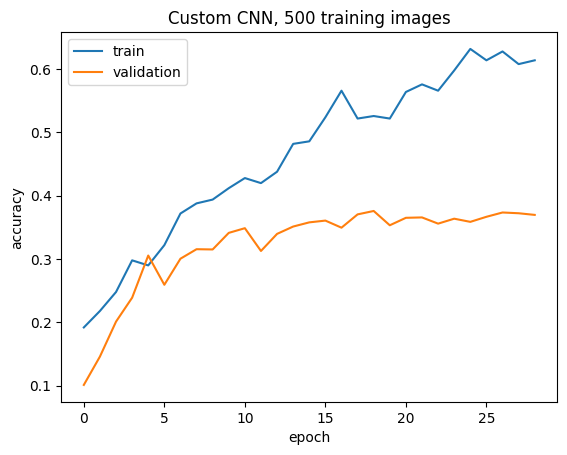

In [ ]:
cnn = build_custom_cnn()
cnn_history, cnn_time, cnn_epochs = train_model(cnn, X_train, y_train, lr=1e-3)
print(f"Training time: {cnn_time:.1f}s over {cnn_epochs} epochs")

plt.plot(cnn_history.history["accuracy"], label="train")
plt.plot(cnn_history.history["val_accuracy"], label="validation")
plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend()
plt.title("Custom CNN, 500 training images")
plt.show()

In [ ]:
cnn_results, cnn_pred = evaluate_model(cnn, X_test, y_test)
print(cnn_results, "trainable:", count_trainable(cnn))

{'test_acc': 0.367, 'macro_f1': 0.3750533728165453, 'latency_ms': np.float64(1.6780779999407969), 'fps': np.float64(595.9198559514399)} trainable: 289194


**B:** MobileNetV2 (ImageNet weights) with inputs resized to 128 px, frozen backbone, new Dense head, 12,810 trainable parameters

In [ ]:
IMG_SIZE = 128

def build_pretrained(augment = False):
  backbone = MobileNetV2(
      include_top=False,
      input_shape=(IMG_SIZE, IMG_SIZE, 3),
      weights="imagenet",
      pooling="avg"
  )
  backbone.trainable = False

  inputs = keras.Input(shape=(32, 32, 3))
  x = inputs
  if augment:
    x = augmentation(x)
  x = layers.Resizing(IMG_SIZE,IMG_SIZE)(x)
  x = layers.Rescaling(1/127.5, offset=-1)(x)
  x = backbone(x, training=False)
  outputs = layers.Dense(10)(x)
  return keras.Model(inputs, outputs, name="mobilenetv2_transfer"),backbone

In [ ]:
fe_model, fe_backbone = build_pretrained()
fe_history, fe_time, fe_epochs = train_model(fe_model, X_train, y_train, lr=1e-3)
print(f"Training time: {fe_time:.1f}s over {fe_epochs} epochs")

fe_results, fe_pred = evaluate_model(fe_model, X_test, y_test)
print(fe_results, "trainable:", count_trainable(fe_model))

Epoch 1/50
16/16 - 20s - 1s/step - accuracy: 0.1940 - loss: 2.4413 - val_accuracy: 0.3708 - val_loss: 1.7925 - learning_rate: 0.0010
Epoch 2/50
16/16 - 2s - 118ms/step - accuracy: 0.5920 - loss: 1.2832 - val_accuracy: 0.5966 - val_loss: 1.1997 - learning_rate: 0.0010
Epoch 3/50
16/16 - 2s - 113ms/step - accuracy: 0.7820 - loss: 0.7731 - val_accuracy: 0.6760 - val_loss: 0.9586 - learning_rate: 0.0010
Epoch 4/50
16/16 - 3s - 178ms/step - accuracy: 0.8620 - loss: 0.5564 - val_accuracy: 0.7100 - val_loss: 0.8609 - learning_rate: 0.0010
Epoch 5/50
16/16 - 2s - 112ms/step - accuracy: 0.9020 - loss: 0.4344 - val_accuracy: 0.7252 - val_loss: 0.8086 - learning_rate: 0.0010
Epoch 6/50
16/16 - 3s - 179ms/step - accuracy: 0.9300 - loss: 0.3503 - val_accuracy: 0.7378 - val_loss: 0.7766 - learning_rate: 0.0010
Epoch 7/50
16/16 - 2s - 125ms/step - accuracy: 0.9520 - loss: 0.2891 - val_accuracy: 0.7438 - val_loss: 0.7559 - learning_rate: 0.0010
Epoch 8/50
16/16 - 2s - 113ms/step - accuracy: 0.9660 - l

**C:** B plus the last 20 backbone layers unfrozen, lr 0.00001, 1,065,290 trainable parameters

In [ ]:
def unfreeze_last_layers(backbone, n_layers=20):
    """Make the last n_layers of the backbone trainable"""
    backbone.trainable = True
    for layer in backbone.layers[:-n_layers]:
        layer.trainable = False

ft_model = fe_model
unfreeze_last_layers(fe_backbone, n_layers=20)
print("trainable after unfreezing:", count_trainable(ft_model))

ft_history, ft_time, ft_epochs = train_model(ft_model, X_train, y_train, lr=1e-5)
ft_total_time = fe_time + ft_time     # lecture 05: include the head-training stage
print(f"Fine-tuning: {ft_time:.1f}s over {ft_epochs} epochs; total {ft_total_time:.1f}s")

ft_results, ft_pred = evaluate_model(ft_model, X_test, y_test)
print(ft_results, "trainable:", count_trainable(ft_model))

trainable after unfreezing: 1065290
Epoch 1/50
16/16 - 33s - 2s/step - accuracy: 0.8500 - loss: 0.5189 - val_accuracy: 0.7646 - val_loss: 0.6964 - learning_rate: 1.0000e-05
Epoch 2/50
16/16 - 2s - 116ms/step - accuracy: 0.9180 - loss: 0.3833 - val_accuracy: 0.7640 - val_loss: 0.7021 - learning_rate: 1.0000e-05
Epoch 3/50
16/16 - 2s - 119ms/step - accuracy: 0.9460 - loss: 0.2995 - val_accuracy: 0.7616 - val_loss: 0.7141 - learning_rate: 1.0000e-05
Epoch 4/50
16/16 - 3s - 177ms/step - accuracy: 0.9680 - loss: 0.2399 - val_accuracy: 0.7574 - val_loss: 0.7278 - learning_rate: 1.0000e-05
Epoch 5/50
16/16 - 2s - 109ms/step - accuracy: 0.9820 - loss: 0.2050 - val_accuracy: 0.7556 - val_loss: 0.7329 - learning_rate: 5.0000e-06
Epoch 6/50
16/16 - 2s - 109ms/step - accuracy: 0.9880 - loss: 0.1866 - val_accuracy: 0.7540 - val_loss: 0.7375 - learning_rate: 5.0000e-06
Epoch 7/50
16/16 - 3s - 174ms/step - accuracy: 0.9900 - loss: 0.1705 - val_accuracy: 0.7534 - val_loss: 0.7417 - learning_rate: 5.00

In [ ]:
RESULTS_PATH = "/content/drive/MyDrive/ugp_proj2_results.csv"

def run_size(n_per_class, augment=False):
    """Train and evaluate A, B and C on n_per_class images per class."""
    X_tr, y_tr = get_train_subset(n_per_class)
    rows, preds = [], {}

    # A: custom CNN
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)
    cnn = build_custom_cnn(augment=augment)
    _, t, ep = train_model(cnn, X_tr, y_tr, lr=1e-3)
    res, preds["custom_cnn"] = evaluate_model(cnn, X_test, y_test)
    rows.append({"model": "custom_cnn", "train_time_s": t, "epochs": ep,
                 "trainable": count_trainable(cnn), **res})

    # B: frozen backbone + new head
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)
    model, backbone = build_pretrained(augment=augment)
    _, t_fe, ep = train_model(model, X_tr, y_tr, lr=1e-3)
    res, preds["feature_extraction"] = evaluate_model(model, X_test, y_test)
    rows.append({"model": "feature_extraction", "train_time_s": t_fe, "epochs": ep,
                 "trainable": count_trainable(model), **res})

    # C: B, unfreeze the last 20 backbone layers
    unfreeze_last_layers(backbone, n_layers=20)
    _, t_ft, ep = train_model(model, X_tr, y_tr, lr=1e-5)
    res, preds["fine_tuning"] = evaluate_model(model, X_test, y_test)
    rows.append({"model": "fine_tuning", "train_time_s": t_fe + t_ft, "epochs": ep,
                 "trainable": count_trainable(model), **res})

    for r in rows:
        r.update({"n_train": len(X_tr), "augment": augment})
    return rows, preds

#Training

In [ ]:
all_results, all_preds = [], {}

for n in [50, 200, 1000, 4500]:              # 500 / 2,000 / 10,000 / 45,000 images
    rows, preds = run_size(n)
    all_results += rows
    all_preds[n] = preds
    pd.DataFrame(all_results).to_csv(RESULTS_PATH, index=False)   # save after each size
    print(f"Done: {n * 10} images")

df = pd.DataFrame(all_results)
df

Epoch 1/50
16/16 - 24s - 1s/step - accuracy: 0.1720 - loss: 2.8427 - val_accuracy: 0.1000 - val_loss: 2.5204 - learning_rate: 0.0010
Epoch 2/50
16/16 - 1s - 44ms/step - accuracy: 0.2100 - loss: 2.3195 - val_accuracy: 0.1332 - val_loss: 2.3337 - learning_rate: 0.0010
Epoch 3/50
16/16 - 1s - 79ms/step - accuracy: 0.2260 - loss: 2.1254 - val_accuracy: 0.1754 - val_loss: 2.1980 - learning_rate: 0.0010
Epoch 4/50
16/16 - 1s - 44ms/step - accuracy: 0.2820 - loss: 2.0219 - val_accuracy: 0.2078 - val_loss: 2.0690 - learning_rate: 0.0010
Epoch 5/50
16/16 - 1s - 44ms/step - accuracy: 0.3060 - loss: 1.9652 - val_accuracy: 0.3072 - val_loss: 1.8606 - learning_rate: 0.0010
Epoch 6/50
16/16 - 1s - 44ms/step - accuracy: 0.3560 - loss: 1.8394 - val_accuracy: 0.3350 - val_loss: 1.7948 - learning_rate: 0.0010
Epoch 7/50
16/16 - 1s - 43ms/step - accuracy: 0.3780 - loss: 1.7429 - val_accuracy: 0.3152 - val_loss: 1.8747 - learning_rate: 0.0010
Epoch 8/50
16/16 - 1s - 43ms/step - accuracy: 0.3800 - loss: 1.

,model,train_time_s,epochs,trainable,test_acc,macro_f1,latency_ms,fps,n_train,augment
0,custom_cnn,47.556074,29,289194,0.4081,0.401128,1.646299,607.422890,500,False
1,feature_extraction,77.868888,30,12810,0.7602,0.760208,7.148591,139.887716,500,False
2,fine_tuning,122.928194,11,1065290,0.7612,0.761185,5.219903,191.574441,500,False
3,custom_cnn,72.605247,50,289194,0.5932,0.590794,1.607324,622.152292,2000,False
4,feature_extraction,77.287708,23,12810,0.8069,0.806677,5.177668,193.137123,2000,False
5,fine_tuning,134.963859,11,1065290,0.8062,0.805601,5.144783,194.371677,2000,False
6,custom_cnn,137.978851,50,289194,0.7664,0.765665,1.664249,600.871444,10000,False
7,feature_extraction,126.493676,19,12810,0.8348,0.834324,5.327110,187.719027,10000,False
8,fine_tuning,258.011438,18,1065290,0.8375,0.837795,8.011720,124.817143,10000,False
9,custom_cnn,452.499150,43,289194,0.8592,0.858651,1.606038,622.650467,45000,False


#Measurments

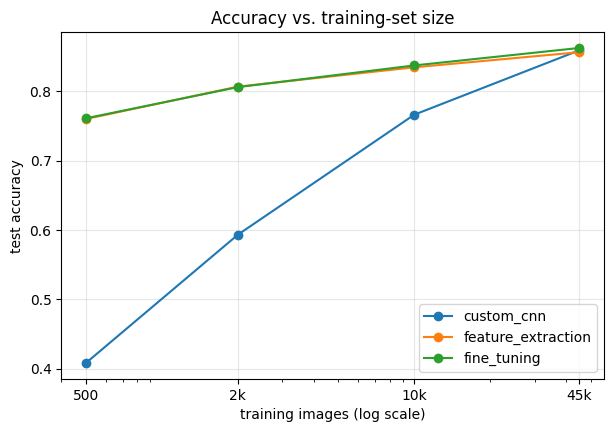

,n_train,model,test_acc,macro_f1,trainable,train_time_s,epochs,latency_ms
0,500,custom_cnn,0.408,0.401,289194,47.556,29,1.646
1,500,feature_extraction,0.760,0.760,12810,77.869,30,7.149
2,500,fine_tuning,0.761,0.761,1065290,122.928,11,5.220
3,2000,custom_cnn,0.593,0.591,289194,72.605,50,1.607
4,2000,feature_extraction,0.807,0.807,12810,77.288,23,5.178
5,2000,fine_tuning,0.806,0.806,1065290,134.964,11,5.145
6,10000,custom_cnn,0.766,0.766,289194,137.979,50,1.664
7,10000,feature_extraction,0.835,0.834,12810,126.494,19,5.327
8,10000,fine_tuning,0.838,0.838,1065290,258.011,18,8.012
9,45000,custom_cnn,0.859,0.859,289194,452.499,43,1.606


In [ ]:
df = pd.read_csv(RESULTS_PATH)

# Main figure: test accuracy vs training-set size
plt.figure(figsize=(7, 4.5))
for name, group in df.groupby("model"):
    plt.plot(group["n_train"], group["test_acc"], marker="o", label=name)
plt.xscale("log")
plt.xticks([500, 2000, 10000, 45000], ["500", "2k", "10k", "45k"])
plt.xlabel("training images (log scale)")
plt.ylabel("test accuracy")
plt.title("Accuracy vs. training-set size")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# Results table for the report
df[["n_train", "model", "test_acc", "macro_f1", "trainable",
    "train_time_s", "epochs", "latency_ms"]].round(3)

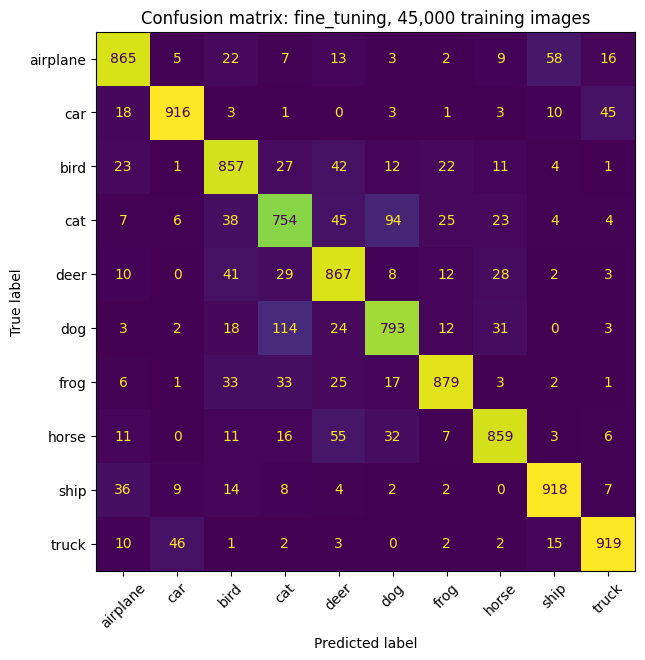

In [ ]:
best = "fine_tuning"
y_pred = all_preds[4500][best]

fig, ax = plt.subplots(figsize=(7, 7))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=class_names,
    xticks_rotation=45, colorbar=False, ax=ax)
ax.set_title(f"Confusion matrix: {best}, 45,000 training images")
plt.show()